# Does a LoRA trained to its plateau become liftable into the decomposition?

## The answer

**Not by training longer.** A rank-8 LoRA trained for a thousand steps on the emoticon task never became readable by the released subcomponents. Its update stayed about as inexpressible as a random one throughout. The lifted state stayed far from the fine-tune's failure on VPD's adversarial check, though above the unchanged model's noise at steps 10 and 100. But by the plateau Δ held about half the update's energy and a third of the trained behaviour. So the lift fails the weak version there.

## What we were trying to test

Five symbols are used throughout:

- $W_0$: the weights of the released 67M-parameter Pile model, the target model before any training.
- a **subcomponent** $c$: one rank-1 matrix $U_c V_c^\top$ of VPD's released decomposition. $V_c$ is the input direction it reads and $U_c$ the output direction it writes. *Alive* subcomponents are the ones Γ ever switches on.
- **Γ**: VPD's causal-importance function. It reads the model's activations and decides which subcomponents each position uses. It is frozen here.
- **Δ**: the residual, the part of each weight matrix the subcomponents do not hold.
- $\delta W = BA$: the LoRA's weight change on one matrix. The rows of $A$ are the input directions the change reads, and $B$ says what it writes for each.

The released decomposition describes $W_0$. We fine-tune $W_0$ with a rank 8 LoRA on all 24 decomposed matrices, teaching it to output the token `o` after an emoticon trigger. The question is whether the decomposition can absorb this change in its subcomponents rather than in Δ. The map we test is the **lift**: the least-norm change $(dU, dV)$ of the alive subcomponents with $dU\,V^\top + U\,dV^\top \approx \delta W$. Whatever no such first-order change can express is left in Δ.

An earlier run lifted this LoRA at step 2, the step where it first learns the task. There, $A$ had not moved from its random start, so it was unclear whether what was seen belonged to that early step or to the LoRA itself. This run trains the same LoRA, with the same recipe and seed, for 1000 steps, until its training loss is flat.

```
LoRA training, one seed  ─────────────────────────────────────────────────────────▶ step
checkpoints:   1   2   3   5   10   30   100   300   1000
  every checkpoint    : how much of δW can the subcomponents express?  how far has A moved?
  steps 10, 100, 1000 : lift and do-nothing states → VPD's checks on Pile, and what Δ holds
```

Held fixed: the released decomposition, Γ, the training data and the LoRA recipe. Varied: the training step.

**At every checkpoint** we measure two things.

- *How much of the change the subcomponents can express.* The update's output energy on the model's own inputs is $\mathbb{E}_x\|\delta W x\|^2$. The **inexpressible share** is the fraction of it that no first-order change of the alive subcomponents can produce. It is 0 when all of the update is expressible and 1 when none is. The same share for a random update of the same matrix is its **isotropic null**. We track the ratio of the two, pooled by energy over 20 matrices, where 1 means "as inexpressible as a random update". The other four matrices are **saturated**: their alive subcomponents read every input direction, so any change there is expressible and the share is always 0.
- *How far the read factor moved.* The mean $|\cos|$ between each row of $A$ and its random start, where 1 means it has not moved.

**At steps 10, 100 and 1000** we build two states and put both through VPD's own checks.

- The **lifted state** described above, and the **do-nothing state**, with δW placed in Δ and the subcomponents untouched. `GOALS.md` rules the do-nothing map out. It shows what each check reads when the subcomponents carry none of the update.
- **The adversarial check on Pile.** VPD's reconstruction KL on 256 Pile validation rows under the worst mask a 20-step search finds. It is reported as a ratio to the released decomposition's value on $W_0$, so 1 means "as faithful as the released decomposition". Its noise floor is the spread of that value over three adversary seeds on $W_0$.
- **What Δ holds.** The share of the trained behaviour that comes from Δ rather than from the subcomponents. The behaviour is the held-out gain in log-odds of `o` at the trigger. The share is 0 if the subcomponents carry all of it, and 1 for the do-nothing state. We also report Δ's share of the update's energy, $\|\Delta'-\Delta_0\|_F^2 / \|\delta W\|_F^2$.

**The control** is a full-weight fine-tune on the same task, lifted at step 10, measured in the earlier run on a different GPU. Its read side is shaped by the data, so it shows what the inexpressible ratio reads for an update the subcomponents can partly read. Its lift is known to fail the adversarial check, so it also shows that the check can fail. Step 10 is that fine-tune's step, so the lift at step 10 here is the like-for-like comparison the earlier run lacked.

## What we expected, and why

**The read side stays random.** We predicted that at step 1000 the inexpressible ratio would still be at least 0.8. A ratio near the fine-tune's 0.50 would have meant $A$ had become shaped by the data. The reasoning: between steps 2 and 100, $A$ moved by 3% while the ratio barely changed. With Adam at a learning rate of 0.001, the gradient on $A$ passes through $B$, and once $B$ has learned the task there is little left to push $A$.

**The lifted state survives the adversary at step 10.** We predicted an adversarial ratio of at most 2. Δ would hold at most a fifth of the behaviour. A ratio of 5 or more would have meant the LoRA's lift is as fragile as the fine-tune's, whose lift read 5.41 at this step. The reasoning: at step 2 the LoRA's update was already twice the fine-tune's step-10 update in relative size, and its lift read 1.13. So the size of the update did not seem to be what made the fine-tune's lift fragile.

**It still survives at the plateau, weakly.** We predicted the same two lines at step 1000, for an update three to five times larger. If step 10 passed and step 1000 read 5 or more, the fragility would be about the update's size after all.

Steps 2 and 100 were also measured in the earlier run, so this run must pass through the same values there.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

R = Path('../experiments/lora_plateau/results')
res = json.loads((R / 'lora_plateau.json').read_text())
pred = json.loads((R / 'predictions.json').read_text())
CK, PS, SC, W0, REF = res['checkpoints'], res['pile_steps'], res['score'], res['W0'], res['ref']
STEPS = sorted(int(s) for s in CK)
PILE = sorted(int(s) for s in PS)
NON_SAT = set(W0['non_saturated'])
BAND = 1 + 3 * W0['pgd_floor']          # the released decomposition's three-floor band on this GPU
FT = REF['ft_lift_step10']              # full fine-tune at step 10, earlier run on an L40

# Earlier run (experiments/lora_matched, L40): values this run's JSON does not carry.
M = json.loads(Path('../experiments/lora_matched/results/lora_matched.json').read_text())
FT_DELTA_SHARE = M['ft']['measured']['lift']['delta_change_frac']                 # fine-tune lift's share of ||dW||^2 in Delta
SEED1_STEP100 = M['lora_s1']['steps']['100']['lift']['routes']['shares']['e_delta']  # same LoRA recipe, seed 1, step 100
FT_PER = M['ft']['measured']['inexpressible']['per_matrix']

LIFT, NOTHING, FTC, REFC = '#2a78d6', '#8a8a86', '#eb6834', '#333333'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.titlesize': 11, 'font.size': 9, 'legend.fontsize': 8, 'legend.frameon': False})

def ck(f):
    return [f(CK[str(s)]) for s in STEPS]

def per(s):
    return CK[str(s)]['inexpressible']['per_matrix']

def all24(p, key):
    # energy-weighted over all matrices; saturated ones read 0
    tot = sum(v['energy'] for v in p.values())
    return sum(v[key] * v['energy'] for v in p.values()) / tot

def table(header, rows):
    out = '| ' + ' | '.join(header) + ' |\n|' + '---|' * len(header) + '\n'
    return Markdown(out + '\n'.join('| ' + ' | '.join(r) + ' |' for r in rows))

first = next(s for s in STEPS if CK[str(s)]['eval']['p_o'] >= 0.9)
print(f"The LoRA learned the task at step {first}: held-out P(o) {CK[str(first)]['eval']['p_o']:.2f}, "
      f"{CK['1000']['eval']['p_o']:.4f} at step 1000.")
print(f"Training loss is flat by the end: mean over steps 301-1000 / mean over 101-300 = {res['plateau_ratio']:.2f}.")
print(f"Released decomposition's adversarial noise floor on this GPU: {W0['pgd_floor']:.3f}, so the three-floor band ends at {BAND:.2f}.")

The LoRA learned the task at step 2: held-out P(o) 0.96, 0.9999 at step 1000.
Training loss is flat by the end: mean over steps 301-1000 / mean over 101-300 = 1.02.
Released decomposition's adversarial noise floor on this GPU: 0.046, so the three-floor band ends at 1.14.


The LoRA learned the task at step 2 and its loss had stopped falling by step 300, so step 1000 is a plateau.

## What we observed

### 1. Does the LoRA's read side ever become readable by the subcomponents?

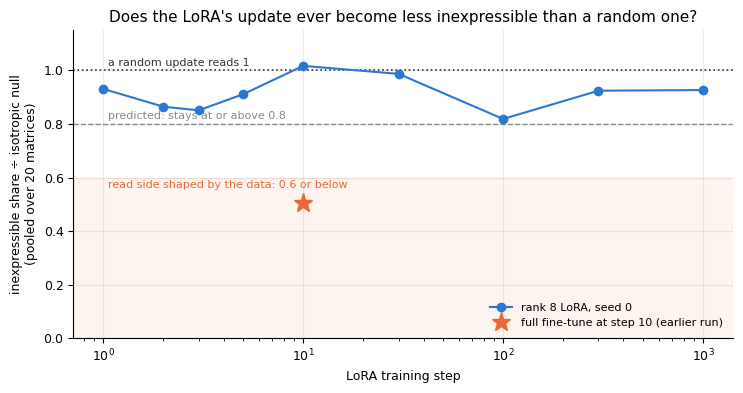

| step | inexpressible ÷ null | A's cosine with its start | read side in the alive span | same, random read side |
|---|---|---|---|---|
| 1 | 0.93 | 1.000 | 0.270 | 0.264 |
| 2 | 0.86 | 1.000 | 0.273 | 0.267 |
| 3 | 0.85 | 0.999 | 0.268 | 0.262 |
| 5 | 0.91 | 0.998 | 0.261 | 0.256 |
| 10 | 1.02 | 0.995 | 0.264 | 0.260 |
| 30 | 0.99 | 0.988 | 0.275 | 0.270 |
| 100 | 0.82 | 0.973 | 0.212 | 0.164 |
| 300 | 0.92 | 0.959 | 0.162 | 0.122 |
| 1000 | 0.93 | 0.902 | 0.127 | 0.102 |

In [2]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.axhspan(0, 0.6, color=FTC, alpha=0.07)
ax.axhline(1.0, color=REFC, ls=':', lw=1.2)
ax.text(1.05, 1.01, 'a random update reads 1', fontsize=8, color=REFC, va='bottom')
ax.axhline(0.8, color=NOTHING, ls='--', lw=1)
ax.text(1.05, 0.81, 'predicted: stays at or above 0.8', fontsize=8, color=NOTHING, va='bottom')
ax.text(1.05, 0.59, 'read side shaped by the data: 0.6 or below', fontsize=8, color=FTC, va='top')
ax.plot(STEPS, ck(lambda c: c['ratio']), 'o-', color=LIFT, label='rank 8 LoRA, seed 0')
ax.plot([10], [FT['inexpressible_ratio']], '*', ms=14, color=FTC, label='full fine-tune at step 10 (earlier run)')
ax.set_xscale('log'); ax.set_ylim(0, 1.15)
ax.set_xlabel('LoRA training step'); ax.set_ylabel('inexpressible share ÷ isotropic null\n(pooled over 20 matrices)')
ax.set_title("Does the LoRA's update ever become less inexpressible than a random one?")
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

display(table(['step', 'inexpressible ÷ null', "A's cosine with its start", 'read side in the alive span', 'same, random read side'],
              [[str(s), f"{CK[str(s)]['ratio']:.2f}", f"{CK[str(s)]['cos_init']['mean']:.3f}",
                f"{CK[str(s)]['read_side']['pooled_in_alive']:.3f}", f"{CK[str(s)]['read_side']['pooled_random']:.3f}"] for s in STEPS]))

The fourth column is the share of the update's squared norm whose read side lies inside the span the alive subcomponents read. The fifth is the same share for a random read side.

**Reading it.** No: at every checkpoint from step 1 to step 1000, the LoRA's update is about as inexpressible as a random update of the same matrices. The blue line stays between 0.82 and 1.02 and never comes near the orange star. That star is the full fine-tune, whose update is half as inexpressible as random. The table shows why: the read factor $A$ keeps a cosine above 0.97 with its random start until step 100. At step 1000 the cosine is still 0.90. From step 100 on, slightly more of the update reads inside the alive span than a random read side would. That small excess does not move the pooled ratio. Steps 2 and 100 match the earlier run to two digits.

### 2. Where does the update's energy go as training continues?

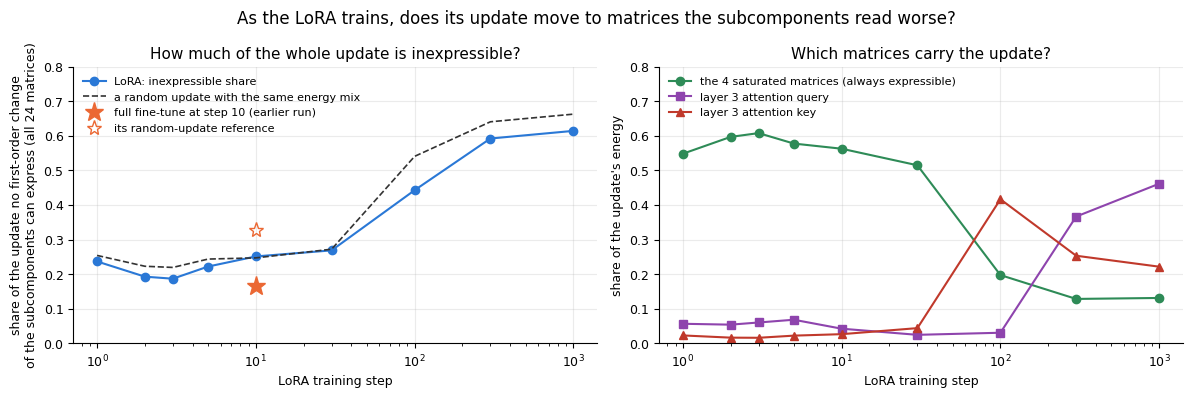

| matrix at step 1000 | share of energy | inexpressible share | random update | read side in alive span vs random |
|---|---|---|---|---|
| layer 3 query | 0.46 | 0.83 | 0.84 | 0.061 vs 0.047 |
| layer 3 key | 0.22 | 0.46 | 0.77 | 0.154 vs 0.078 |

In [3]:
fig, (l, r) = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
l.plot(STEPS, [all24(per(s), 'omega_act') for s in STEPS], 'o-', color=LIFT, label='LoRA: inexpressible share')
l.plot(STEPS, [all24(per(s), 'null_act') for s in STEPS], '--', color=REFC, lw=1.2, label='a random update with the same energy mix')
l.plot([10], [all24(FT_PER, 'omega_act')], '*', ms=14, color=FTC, label='full fine-tune at step 10 (earlier run)')
l.plot([10], [all24(FT_PER, 'null_act')], '*', ms=11, mfc='none', color=FTC, label="its random-update reference")
l.set_ylim(0, 0.8); l.set_ylabel('share of the update no first-order change\nof the subcomponents can express (all 24 matrices)')
l.set_title('How much of the whole update is inexpressible?'); l.legend(loc='upper left')
sat = [sum(v['energy_share'] for k, v in per(s).items() if k not in NON_SAT) for s in STEPS]
r.plot(STEPS, sat, 'o-', color='#2e8b57', label='the 4 saturated matrices (always expressible)')
r.plot(STEPS, [per(s)['h.3.attn.q_proj']['energy_share'] for s in STEPS], 's-', color='#8e44ad', label='layer 3 attention query')
r.plot(STEPS, [per(s)['h.3.attn.k_proj']['energy_share'] for s in STEPS], '^-', color='#c0392b', label='layer 3 attention key')
r.set_ylim(0, 0.8); r.set_ylabel("share of the update's energy")
r.set_title('Which matrices carry the update?'); r.legend(loc='upper left')
for ax in (l, r):
    ax.set_xscale('log'); ax.set_xlabel('LoRA training step')
fig.suptitle("As the LoRA trains, does its update move to matrices the subcomponents read worse?", fontsize=12)
plt.tight_layout(); plt.show()

rs = CK['1000']['read_side']['per_matrix']
display(table(['matrix at step 1000', 'share of energy', 'inexpressible share', 'random update', 'read side in alive span vs random'],
              [[name, f"{per(1000)[key]['energy_share']:.2f}", f"{per(1000)[key]['omega_act']:.2f}", f"{per(1000)[key]['null_act']:.2f}",
                f"{rs[key]['in_alive']:.3f} vs {rs[key]['random']:.3f}"]
               for name, key in (('layer 3 query', 'h.3.attn.q_proj'), ('layer 3 key', 'h.3.attn.k_proj'))]))

**Reading it.** Yes, and that move, not the read side, drives the rise in the whole update's inexpressible share. In the left panel the share over all 24 matrices climbs from about 0.2 to about 0.6. The dashed random reference climbs with it. The LoRA tracks its reference at every step, whereas the fine-tune sits at half of its own. The right panel shows where the energy went. Until step 30 more than half sat on the four saturated matrices, where any update is expressible. By step 100 it had moved to the layer-3 attention key, and by step 1000 to the layer-3 attention query. The query's update is as inexpressible as a random one. The key is the one matrix where the update became partly readable.

### 3. Does the lifted state pass VPD's adversarial check on Pile?

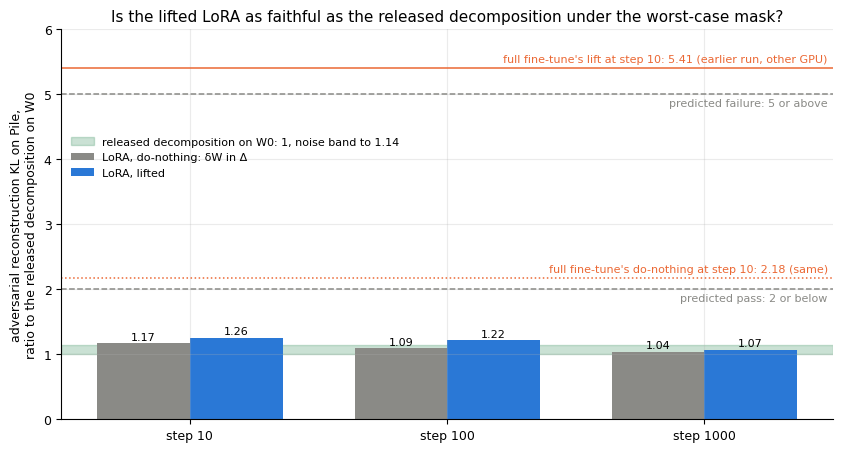

| step | state | adversarial | stochastic mask | CI-masked | all masks on, no Δ |
|---|---|---|---|---|---|
| 10 | do-nothing | 1.17 | 1.01 | 1.01 | 2.01 |
| 10 | lifted | 1.26 | 1.01 | 1.01 | 1.35 |
| 100 | do-nothing | 1.09 | 1.00 | 1.00 | 1.99 |
| 100 | lifted | 1.22 | 1.00 | 1.00 | 1.27 |
| 1000 | do-nothing | 1.04 | 1.00 | 1.00 | 1.50 |
| 1000 | lifted | 1.07 | 1.00 | 1.00 | 1.21 |

In [4]:
x = np.arange(len(PILE)); w = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.axhspan(1, BAND, color='#2e8b57', alpha=0.25, label=f'released decomposition on W0: 1, noise band to {BAND:.2f}')
for y, lab, col, ls, va in ((2, 'predicted pass: 2 or below', NOTHING, '--', 'top'), (5, 'predicted failure: 5 or above', NOTHING, '--', 'top'),
                            (FT['pgd_ratio'], f"full fine-tune's lift at step 10: {FT['pgd_ratio']:.2f} (earlier run, other GPU)", FTC, '-', 'bottom'),
                            (FT['nothing_pgd_ratio'], f"full fine-tune's do-nothing at step 10: {FT['nothing_pgd_ratio']:.2f} (same)", FTC, ':', 'bottom')):
    ax.axhline(y, color=col, ls=ls, lw=1.1)
    ax.text(len(PILE) - 0.52, y + (0.05 if va == 'bottom' else -0.05), lab, fontsize=8, color=col, va=va, ha='right')
nothing = [PS[str(s)]['nothing']['pile']['pgd_kl'] for s in PILE]
lift = [PS[str(s)]['lift']['pile']['pgd_kl'] for s in PILE]
ax.bar(x - w / 2, nothing, w, color=NOTHING, label='LoRA, do-nothing: δW in Δ')
ax.bar(x + w / 2, lift, w, color=LIFT, label='LoRA, lifted')
for i in range(len(PILE)):
    ax.text(x[i] - w / 2, nothing[i] + 0.05, f'{nothing[i]:.2f}', ha='center', fontsize=8)
    ax.text(x[i] + w / 2, lift[i] + 0.05, f'{lift[i]:.2f}', ha='center', fontsize=8)
ax.set_xticks(x, [f'step {s}' for s in PILE]); ax.set_xlim(-0.5, len(PILE) - 0.5); ax.set_ylim(0, 6)
ax.set_ylabel('adversarial reconstruction KL on Pile,\nratio to the released decomposition on W0')
ax.set_title('Is the lifted LoRA as faithful as the released decomposition under the worst-case mask?')
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.75))
plt.tight_layout(); plt.show()

names = {'pgd_kl': 'adversarial', 'stochastic_kl': 'stochastic mask', 'ci_masked_kl': 'CI-masked', 'unmasked_kl': 'all masks on, no Δ'}
display(table(['step', 'state'] + list(names.values()),
              [[str(s), arm.replace('nothing', 'do-nothing').replace('lift', 'lifted')] + [f"{PS[str(s)][arm]['pile'][k]:.2f}" for k in names]
               for s in PILE for arm in ('nothing', 'lift')]))

Every column is a ratio to the released decomposition on $W_0$ on the same rows, so 1 means no change. The last column runs the subcomponents alone, all switched on and without Δ.

**Reading it.** The lifted state stays far below the fine-tune's failure, but it is less faithful than the released decomposition at steps 10 and 100. There it reads 1.26 and 1.22, while the green band of three noise floors on this card ends at 1.14. At step 1000 it reads 1.07, inside the band. All three are well under the filed pass line of 2 and far from the fine-tune's 5.41. The grey bars show that leaving δW in Δ reads slightly lower than the lift at every step. So putting the LoRA's update into the subcomponents never helps on this check. The fine-tune's lines come from another GPU whose noise band was four times wider, so the comparison with them is rough.

### 4. How much of the trained behaviour does the lift leave in Δ?

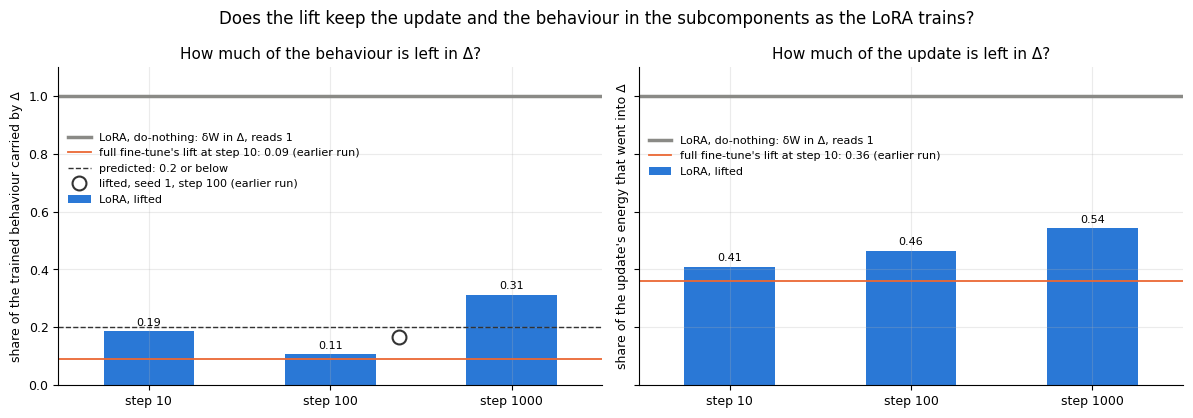

In [5]:
x = np.arange(len(PILE)); w = 0.36
fig, (l, r) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
panels = ((l, lambda a: a['routes']['shares']['e_delta'], FT['e_delta'], 'share of the trained behaviour carried by Δ',
           'predicted: 0.2 or below'),
          (r, lambda a: a['delta_change_frac'], FT_DELTA_SHARE, "share of the update's energy that went into Δ", None))
for ax, f, ft, ylab, line in panels:
    nothing = [f(PS[str(s)]['nothing']) for s in PILE]
    lift = [f(PS[str(s)]['lift']) for s in PILE]
    assert all(abs(v - 1) < 1e-6 for v in nothing)
    ax.axhline(1, color=NOTHING, lw=2.5, label='LoRA, do-nothing: δW in Δ, reads 1')
    ax.bar(x, lift, 0.5, color=LIFT, label='LoRA, lifted')
    for i in range(len(PILE)):
        ax.text(x[i], lift[i] + 0.02, f'{lift[i]:.2f}', ha='center', fontsize=8)
    ax.axhline(ft, color=FTC, lw=1.3, label=f"full fine-tune's lift at step 10: {ft:.2f} (earlier run)")
    if line:
        ax.axhline(0.2, color=REFC, ls='--', lw=1, label=line)
    ax.legend(loc='center left', bbox_to_anchor=(0, 0.72))
    ax.set_xticks(x, [f'step {s}' for s in PILE]); ax.set_xlim(-0.5, len(PILE) - 0.5); ax.set_ylim(0, 1.1)
    ax.set_ylabel(ylab)
l.plot([1.38], [SEED1_STEP100], 'o', mfc='none', ms=10, mew=1.5, color=REFC, label='lifted, seed 1, step 100 (earlier run)')
l.legend(loc='center left', bbox_to_anchor=(0, 0.68))
l.set_title('How much of the behaviour is left in Δ?'); r.set_title('How much of the update is left in Δ?')
fig.suptitle('Does the lift keep the update and the behaviour in the subcomponents as the LoRA trains?', fontsize=12)
plt.tight_layout(); plt.show()

**Reading it.** No, and it gets worse at the plateau. In the left panel Δ carries 0.19 of the trained behaviour at step 10 and 0.11 at step 100. By step 1000 it carries 0.31, above the filed 0.2 line and three times the fine-tune's lift. The hollow circle is a second seed from an earlier run, and it shows seeds differing by about 0.06 at step 100. The rise at the plateau is larger than that, but no second seed was trained this far. In the right panel, Δ's share of the update's energy rises at every step, from 0.41 to 0.54. The fine-tune's lift leaves 0.36. The rise in behaviour coincides with the energy moving onto the layer-3 query, but one run cannot show that it is the cause.

## What we learned

Training a LoRA longer does not make its update readable by the released subcomponents. Its read factor stays close to its random start, and its update stays about as inexpressible as a random one at every step from 1 to 1000. The lifted state passes VPD's adversarial check on Pile, far below where the full fine-tune's lift failed. So for a LoRA, the faithfulness half of the weak version is not the obstacle. The obstacle is the other half: by the plateau Δ holds half of the update's energy and a third of the trained behaviour. For `GOALS.md` this means the lift fails the weak version for a LoRA, and fails it most clearly at the plateau, the last step we measured.

## How compelling is the evidence

- **One seed, one task, one GPU.** The task is the emoticon task, which the model already does weakly. The earlier run's second seed left 0.17 of the behaviour in Δ at step 100, against 0.11 here, so seeds do move this number.
- **The control was not rerun.** The fine-tune's numbers come from the earlier run on an L40. There, the released decomposition's adversarial noise floor was 21%, against 4.6% on the L40S used here. The fine-tune's lift sits far above the filed failure line, but the like-for-like comparison on one card is not in this run.
- **The adversarial check uses one adversary seed per state.** Its floor is measured on $W_0$ only.
- **Pile checks see ordinary text.** The Pile rows contain almost no trigger positions, so they test the decomposition's account of the old model. The trained behaviour is measured only by the share left in Δ, on held-out trigger windows.
- **The inexpressible share is blind to behaviour.** An inexpressible part can still be redundant. The pooled ratio also leaves out the saturated matrices, which is why claim 2 uses the share over all 24.
- **Reproduction.** Steps 2 and 100 match the earlier run to two digits in the inexpressible ratio and in $A$'s movement.
- **Not measured:** VPD's sparsity loss on the lifted states.

## Surprises

- **The plateau prediction was missed on its Δ half.** We filed that the lift would pass at step 1000 on both lines. The adversarial half passed, and more easily than at step 10. But the share of the behaviour in Δ, which had fallen from 0.22 at step 2 to 0.11 at step 100, rose to 0.31. We do not know why. The rise coincides with the update's energy moving onto layer 3's attention query matrix, whose update is as inexpressible as a random one.
- **The lift never beats doing nothing on the adversarial check.** At every step the lifted state reads slightly worse than the do-nothing state.
- **On this GPU the lift is not inside the noise band at steps 10 and 100.** Both points sit about five floors above the released decomposition. They are still well under the filed pass line and the fine-tune's value.
- **The subcomponents alone do not reproduce the lifted model on Pile.** We switched every subcomponent on and removed Δ. The lifted state's KL was then 20% to 35% above the released decomposition's. Leaving δW in Δ doubles it at steps 10 and 100.

## What next

1. **Run the fine-tune control on the same card.** If its lift reads near 5 at step 10 on an L40S too, the contrast with the LoRA stands. If it reads close to the LoRA's value, the contrast was the GPU.
2. **Train a second LoRA seed to the plateau.** If the share of the behaviour in Δ stays near a third, the rise is real. If it falls back near a tenth, it was seed noise.
3. **Shape the LoRA's read side on purpose,** for example a higher learning rate on $A$ alone, after `/design`. If the inexpressible ratio falls towards the fine-tune's half and Δ's share falls with it, readability is the lever.

## Scorecard

The table below lists the three filed predictions. P1 and P2 were filed as passes and passed. P3 was filed as a weak pass and reads neither: its Pile half passed, but e_Δ came out at 0.31 against the 0.2 line. The gates held: G1 learned at step 2, G2 the lifted state reproduces the LoRA's model to 5e-6 in P(o), G3 plateau ratio 1.02.

In [6]:
verdict = lambda p: 'pass' if p['pass'] else ('null' if p['null'] else 'neither')
filed = {p['id'].split('_')[0]: p for p in pred['predictions']}
claim = {'P1': 'read side stays random at step 1000', 'P2': 'lift survives at step 10', 'P3': 'lift survives at step 1000'}
read = {'P1': f"ratio {SC['P1']['ratio']:.2f}",
        'P2': f"PGD {SC['P2']['pgd_lift']:.2f}, e_Δ {SC['P2']['e_delta']:.3f}",
        'P3': f"PGD {SC['P3']['pgd_lift']:.2f}, e_Δ {SC['P3']['e_delta']:.2f}"}
display(table(['id', 'claim', 'rule: pass / null', 'read', 'verdict'],
              [[k, claim[k], f"{filed[k]['pass'].split(' (')[0]} / {filed[k]['null'].split(' (')[0]}", read[k], verdict(SC[k])]
               for k in ('P1', 'P2', 'P3')]))

| id | claim | rule: pass / null | read | verdict |
|---|---|---|---|---|
| P1 | read side stays random at step 1000 | ratio >= 0.8 / ratio <= 0.6 | ratio 0.93 | pass |
| P2 | lift survives at step 10 | Pile PGD ratio <= 2 and e_delta <= 0.2 / Pile PGD ratio >= 5 | PGD 1.26, e_Δ 0.186 | pass |
| P3 | lift survives at step 1000 | Pile PGD ratio <= 2 and e_delta <= 0.2 / Pile PGD ratio >= 5 | PGD 1.07, e_Δ 0.31 | neither |

## Not run

- The full fine-tune on the same GPU at step 10, the like-for-like control for the adversarial comparison.
- A second LoRA seed to the plateau, which decides whether the rise of Δ's share is real.
- A higher learning rate on $A$ alone.
- A per-step lift in which the subcomponents follow the LoRA step by step; its tolerance rule is undecided.
- VPD's sparsity loss on any lifted state, any task other than the emoticon task, and any update of Γ.

**Provenance.** Results `experiments/lora_plateau/results/lora_plateau.json`; predictions `experiments/lora_plateau/results/predictions.json`, filed before training; code `experiments/lora_plateau/run.py`; report `reports/analyses/2026-10-19_analysis_lora-plateau.md`. Scored run on a RunPod L40S: 1872 seconds, about $0.70. The fine-tune reference and the seed-1 values come from `experiments/lora_matched/results/lora_matched.json`, measured on an L40.